# Equal-Weighted S&P 500 Portfolio Strategy

This notebook constructs an equal-weight portfolio across S&P 500 stocks.
Given a portfolio size, it calculates the number of shares to buy for each stock
and visualizes the allocation.

In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import time
import math
plt.style.use('ggplot')

## 1. Load S&P 500 Tickers and Fetch Price Data

We load the first 50 tickers (reduced from 300 for faster notebook execution)
and fetch current prices and market caps from Yahoo Finance.

In [3]:
stocks = pd.read_csv('../../data/sp_500_stocks.csv')
ticker_list = stocks['Ticker'].tolist()[:50]

list_of_rows = []
print(f'Extracting {len(ticker_list)} stock data...')
for ticker in ticker_list:
    try:
        stock = yf.Ticker(ticker)
        price = stock.info.get('regularMarketPrice')
        market_cap = stock.info.get('marketCap')
        sector = stock.info.get('sector', 'Unknown')
        final_market_cap = math.floor(market_cap) if market_cap is not None else None
        list_of_rows.append({
            'Symbol': ticker,
            'Stock Price': price,
            'Market Capitalization': final_market_cap,
            'Sector': sector
        })
        time.sleep(0.5)
    except Exception:
        print(f'Could not obtain data for {ticker}.')

df = pd.DataFrame(list_of_rows)
df.dropna(inplace=True, subset=['Stock Price'])
print(f'Successfully fetched data for {len(df)} stocks.')
df.head(10)

Extracting 50 stock data...


HTTP Error 404: 


Successfully fetched data for 44 stocks.


,Symbol,Stock Price,Market Capitalization,Sector
0,AAPL,248.80,3.656844e+12,Technology
1,ABBV,209.40,3.703788e+11,Healthcare
4,ABT,103.99,1.807016e+11,Healthcare
5,ACN,192.60,1.185328e+11,Technology
6,ADBE,234.84,9.572945e+10,Technology
7,ADI,307.44,1.500935e+11,Technology
8,ADM,72.23,3.480728e+10,Consumer Defensive
9,ADP,201.25,8.139531e+10,Technology
10,ADSK,229.84,4.872608e+10,Technology
11,AEE,108.72,3.005287e+10,Utilities


## 2. Calculate Equal-Weight Position Sizes

Given a portfolio value of $100,000, we divide equally across all stocks
and calculate shares to buy.

In [4]:
portfolio_value = 100000
position_size = portfolio_value / len(df)
df['Number of Shares To Buy'] = (position_size / df['Stock Price']).astype(float)
df['Position Value'] = df['Number of Shares To Buy'] * df['Stock Price']
print(f'Portfolio Value: ${portfolio_value:,.0f}')
print(f'Number of Stocks: {len(df)}')
print(f'Position Size per Stock: ${position_size:,.2f}')
df[['Symbol', 'Stock Price', 'Market Capitalization', 'Number of Shares To Buy']].head(15)

Portfolio Value: $100,000
Number of Stocks: 44
Position Size per Stock: $2,272.73


,Symbol,Stock Price,Market Capitalization,Number of Shares To Buy
0,AAPL,248.80,3.656844e+12,9.134756
1,ABBV,209.40,3.703788e+11,10.853521
4,ABT,103.99,1.807016e+11,21.855248
5,ACN,192.60,1.185328e+11,11.800245
6,ADBE,234.84,9.572945e+10,9.677769
7,ADI,307.44,1.500935e+11,7.392425
8,ADM,72.23,3.480728e+10,31.465143
9,ADP,201.25,8.139531e+10,11.293055
10,ADSK,229.84,4.872608e+10,9.888302
11,AEE,108.72,3.005287e+10,20.904408


## 3. Visualize Portfolio Allocation

Compare the equal-weight allocation against a cap-weighted allocation to illustrate
the difference in diversification.

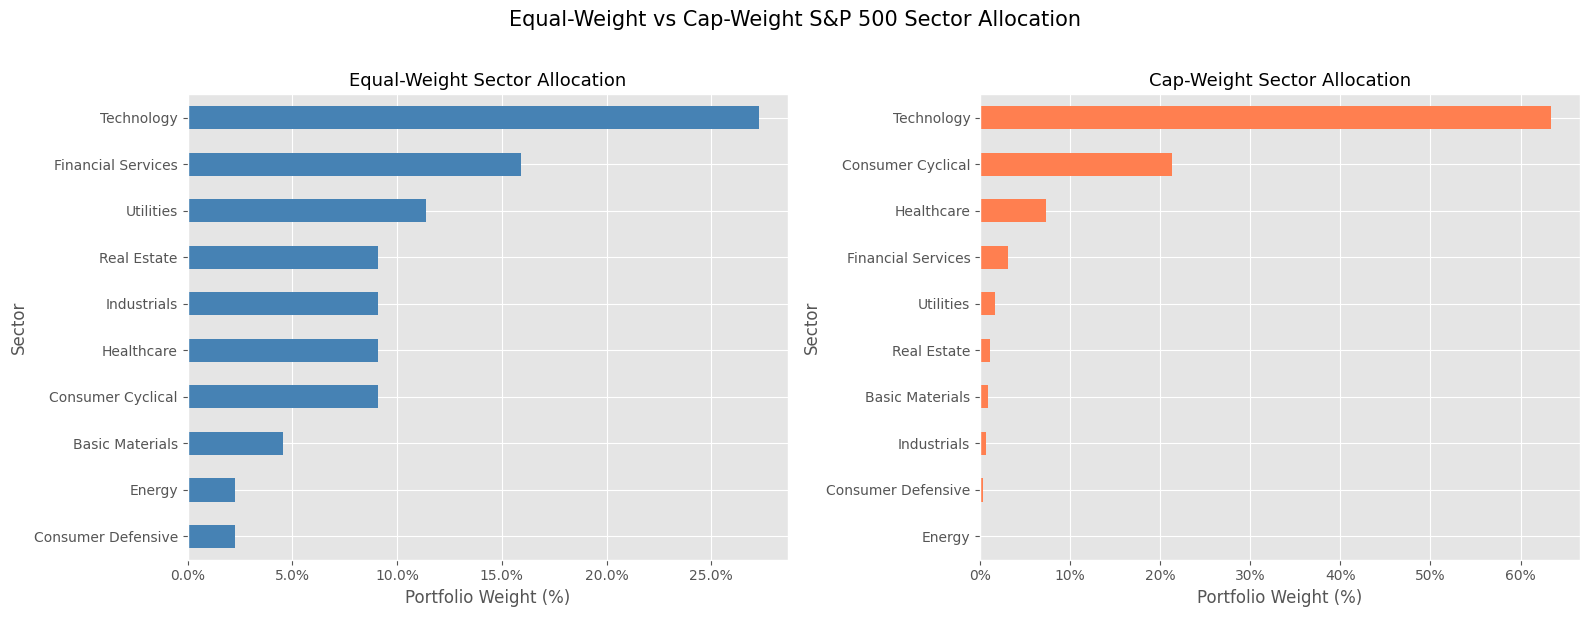

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Equal-Weight Allocation
sector_equal = df.groupby('Sector')['Position Value'].sum()
sector_equal_pct = sector_equal / sector_equal.sum() * 100
sector_equal_pct.sort_values(ascending=True).plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Equal-Weight Sector Allocation', fontsize=13)
axes[0].set_xlabel('Portfolio Weight (%)')
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter())

# Cap-Weight Allocation
sector_cap = df.groupby('Sector')['Market Capitalization'].sum()
sector_cap_pct = sector_cap / sector_cap.sum() * 100
sector_cap_pct.sort_values(ascending=True).plot(kind='barh', ax=axes[1], color='coral')
axes[1].set_title('Cap-Weight Sector Allocation', fontsize=13)
axes[1].set_xlabel('Portfolio Weight (%)')
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter())

plt.suptitle('Equal-Weight vs Cap-Weight S&P 500 Sector Allocation', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('../../results/equal_weight_sector_allocation.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Top Holdings Comparison

In a cap-weighted portfolio, the largest companies dominate. Equal-weighting
distributes capital more evenly, reducing single-stock concentration risk.

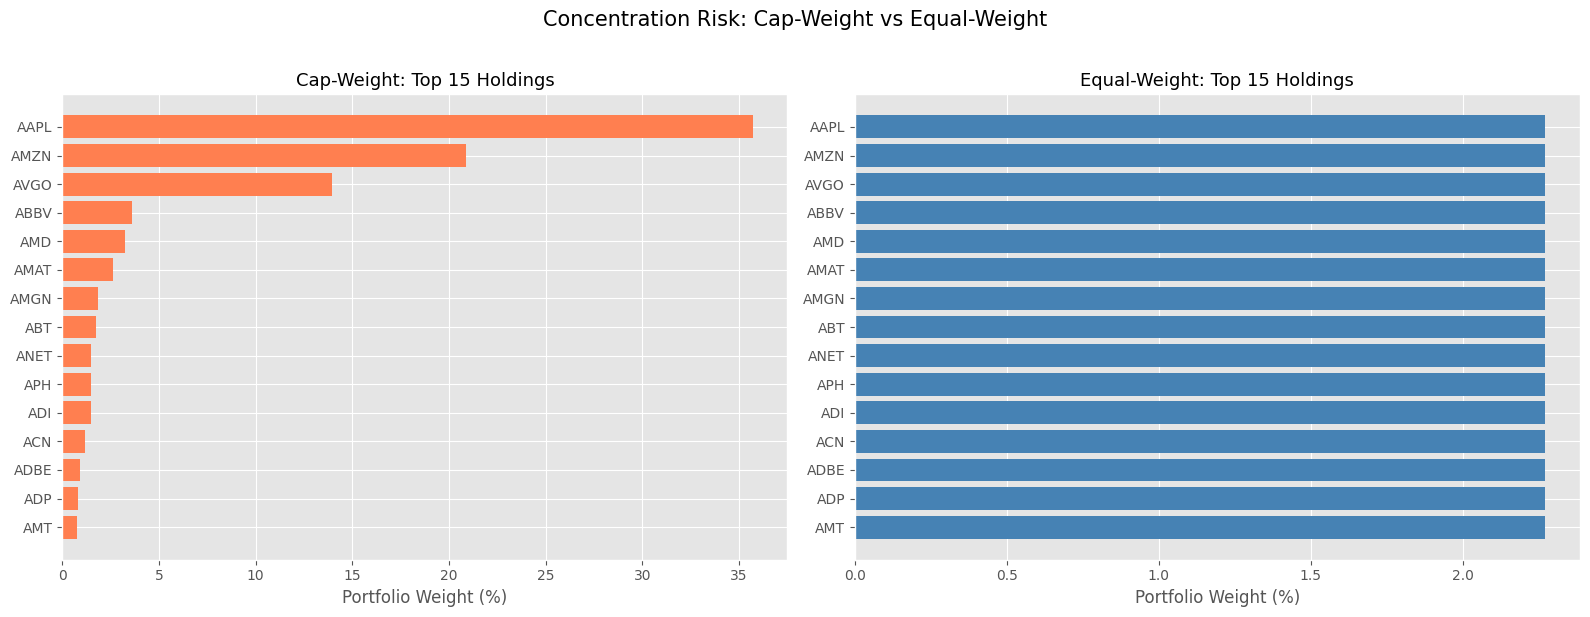

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_n = 15
# Cap-Weight: top stocks dominate
cap_sorted = df.nlargest(top_n, 'Market Capitalization')
cap_weight = cap_sorted['Market Capitalization'] / df['Market Capitalization'].sum() * 100
axes[0].barh(cap_sorted['Symbol'], cap_weight, color='coral')
axes[0].set_title(f'Cap-Weight: Top {top_n} Holdings', fontsize=13)
axes[0].set_xlabel('Portfolio Weight (%)')
axes[0].invert_yaxis()

# Equal-Weight: all stocks equal
equal_weight_pct = 100 / len(df)
axes[1].barh(cap_sorted['Symbol'], [equal_weight_pct] * top_n, color='steelblue')
axes[1].set_title(f'Equal-Weight: Top {top_n} Holdings', fontsize=13)
axes[1].set_xlabel('Portfolio Weight (%)')
axes[1].invert_yaxis()

plt.suptitle('Concentration Risk: Cap-Weight vs Equal-Weight', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('../../results/equal_weight_concentration.png', dpi=150, bbox_inches='tight')
plt.show()